In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchstain
from PIL import Image
from torchvision.transforms import v2

from src.config import DataConfig, TransformConfig
from src.features.dataframe import create_dataframe
from src.features.stats import build_reinhard
from src.features.transform import CLAHETransform, ReinhardTransform, ResizeWithPad, ToUnitRange
from src.tasks import get_task

In [99]:
dataset_mean = np.array([0.6001, 0.5036, 0.5408])
dataset_std = np.array([0.2312, 0.2576, 0.2105])


def build_transform(
    cfg: TransformConfig, reinhard_normalizer=None, jitter: bool = True, random_state=None
):
    steps: list = [ResizeWithPad(cfg.img_size, fill=255)]
    if cfg.jpeg:
        steps.append(v2.JPEG(cfg.jpeg_quality))
    steps.append(ToUnitRange())
    if reinhard_normalizer is not None:
        steps.append(ReinhardTransform(reinhard_normalizer))
    if cfg.clahe:
        steps.append(CLAHETransform(cfg.clahe_clip_limit, cfg.clahe_grid_size))
    if jitter:
        if random_state is not None:
            torch.manual_seed(random_state)
        steps += [
            v2.ColorJitter(brightness=cfg.brightness_delta),
            v2.ColorJitter(contrast=cfg.contrast_delta),
        ]
    mean = dataset_mean.tolist() if torch.is_tensor(dataset_mean) else list(dataset_mean)
    std = dataset_std.tolist() if torch.is_tensor(dataset_std) else list(dataset_std)
    steps.append(v2.Normalize(mean=mean, std=std))
    return v2.Compose(steps)


In [100]:
task = get_task("dataset")
DataConfig.model_construct()
data_config = DataConfig(n_images=2000, stratify="dataset")
transform_config = TransformConfig(jpeg_quality=30, p_rotation=0, brightness_delta=0.2, p_flip=0)
df = create_dataframe(data_config, task)
normalizer = build_reinhard(df, transform_config, seed=42)
normalizer = torchstain.normalizers.ReinhardNormalizer(backend="torch")
normalizer.target_means = np.array([79.3602, 12.1453, -1.5495])
normalizer.target_stds = np.array([16.9211, 13.2902, 16.5128])
dataset_mean = np.array([0.6001, 0.5036, 0.5408])
dataset_std = np.array([0.2312, 0.2576, 0.2105])
tf = build_transform(
    transform_config,
    reinhard_normalizer=normalizer,
)


In [101]:
params = {
    "original": {
        "reinhard_normalizer": None,
        "use_clahe": False,
        "use_jpeg": False,
        "training": False,
    },
    "reinhard+clahe": {
        "reinhard_normalizer": normalizer,
        "use_clahe": True,
        "use_jpeg": False,
        "training": False,
    },
    "transformed": {
        "reinhard_normalizer": normalizer,
        "use_clahe": True,
        "use_jpeg": False,
        "training": True,
    },
    "jpeg20": {
        "reinhard_normalizer": normalizer,
        "use_clahe": True,
        "use_jpeg": True,
        "training": True,
        "jpeg_quality": 20,
    },
    "jpeg30": {
        "reinhard_normalizer": normalizer,
        "use_clahe": True,
        "use_jpeg": True,
        "training": True,
        "jpeg_quality": 30,
    },
    "jpeg40": {
        "reinhard_normalizer": normalizer,
        "use_clahe": True,
        "use_jpeg": True,
        "training": True,
        "jpeg_quality": 40,
    },
    "jpeg50": {
        "reinhard_normalizer": normalizer,
        "use_clahe": True,
        "use_jpeg": True,
        "training": True,
        "jpeg_quality": 50,
    },
}

In [102]:
def to_hwc(t):
    t = t.detach().cpu().float()
    if t.shape[0] in (1, 3):  # CHW -> HWC
        t = t.permute(1, 2, 0)
    if t.max() > 1.5:  # uint8 -> [0,1]
        t = t / 255.0
    return t.clamp(0, 1).numpy()


In [103]:
def display_transforms(img_a, img_b, datasets=["barcelona", "munich"], random_state=None):
    n = len(params)
    fig, axes = plt.subplots(
        2, n, figsize=(3 * n, 2 * 3.4), constrained_layout=True
    )  # , figsize=(12, 3 * ncols)
    fig.suptitle("Comparaison des transformations", fontsize=16)
    for i, img in enumerate([img_a, img_b]):
        for j, (ax, (name, param)) in enumerate(zip(axes[i], params.items())):
            config = TransformConfig(
                jpeg_quality=30,
                p_rotation=0,
                brightness_delta=0.2,
                p_flip=0,
                clahe=param["use_clahe"],
                jpeg=param["use_jpeg"],
            )
            transform = build_transform(
                config,
                reinhard_normalizer=param["reinhard_normalizer"],
                jitter=param["training"],
                random_state=random_state,
            )
            out = transform(img)
            out = (out * dataset_std[:, None, None] + dataset_mean[:, None, None]).clamp(0, 1)

            ax.imshow(to_hwc(out))
            ax.set_title(name)
            if j == 0:
                ax.set_ylabel(datasets[i])
                ax.set_yticks([])
                ax.set_xticks([])
            else:
                ax.axis("off")


In [104]:
def load_image_tensor(path):
    with Image.open(path) as img:
        img = img.convert("RGB")
    return v2.functional.pil_to_tensor(img)

/var/folders/m_/b04ywwq12g933cgpc9bdd6jm0000gn/T/ipykernel_31064/1047872813.py:24: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  out = (out * dataset_std[:, None, None] + dataset_mean[:, None, None]).clamp(0, 1)


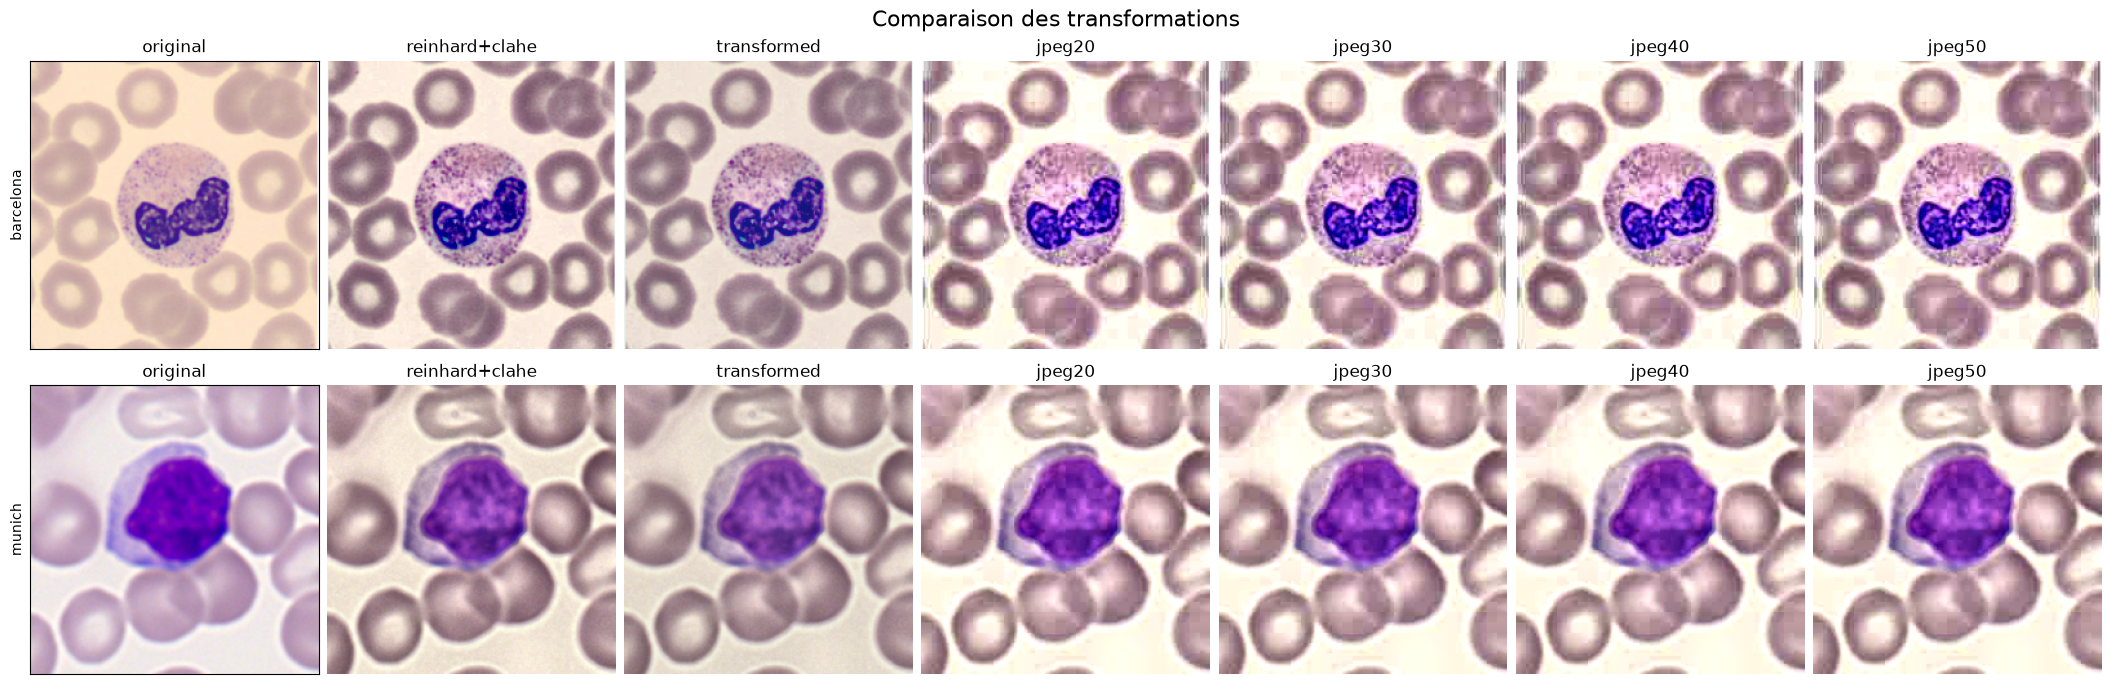

In [105]:
seed = 2
img_barcelona = load_image_tensor(
    df[df.dataset == "barcelona"].sample(1, random_state=seed).iloc[0].path
)
img_munich = load_image_tensor(df[df.dataset == "munich"].sample(1, random_state=seed).iloc[0].path)

display_transforms(img_barcelona, img_munich, random_state=seed)


In [ ]:
from pathlib import Path

import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", None)

leaderboard_path = Path.cwd().parent / "results" / "leaderboard.csv"


In [ ]:
def refresh_grid(run_name):
    df = pd.read_csv(leaderboard_path, parse_dates=["timestamp"])
    df_run = df[df.name == run_name]
    df_run_grid = df_run.loc[:, df_run.nunique(dropna=False) > 1]
    return df, df_run_grid


def show_grid_results(df_run_grid, task: str = "type", n_best=25):
    if task == "type":
        by = "val_f1_macro"
        asc = False
    else:
        by = "val_acc"
        asc = True
    display(
        df_run_grid.sort_values(by=by, ascending=asc)
        # .sort_values(by="timestamp")
        .sort_index(axis=1)
        .head(n_best)
    )
    print(len(df_run_grid))

In [5]:
run_name = "grid_search_dataset_full_1"
df, df_grid = refresh_grid(run_name)
show_grid_results(df_grid, task="dataset")

,duration_s,run_dir,timestamp,transform.blur_kernel_size,transform.blur_sigma_max,transform.clahe,transform.clahe_clip_limit,transform.clahe_grid_size,transform.contrast_delta,transform.jpeg,transform.jpeg_quality,transform.p_blur,transform.p_contrast,transform.p_flip,transform.p_rotation,transform.reinhard,val_acc,val_loss
598,39.8,results/runs/f1895e08,2026-09-07 12:57:01,9.0,4.0,False,0.0,0,0.0,False,0,0.5,0.0,0.00,0.00,True,0.870588,0.327188
705,41.1,results/runs/53e39e97,2026-09-07 15:25:26,5.0,2.0,False,0.0,0,0.0,False,0,0.5,0.0,0.00,0.50,True,0.929412,0.136488
678,46.5,results/runs/73f53f6c,2026-09-07 14:50:40,33.0,100.0,False,0.0,0,0.0,True,50,0.0,0.0,0.90,0.90,True,0.949020,0.183680
697,41.9,results/runs/23e42aa2,2026-09-07 15:15:58,5.0,8.0,False,0.0,0,0.0,False,0,0.9,0.0,0.90,0.90,True,0.960784,0.109994
650,40.7,results/runs/1b7189f0,2026-09-07 14:14:10,9.0,8.0,False,0.0,0,0.0,False,0,0.9,0.0,0.00,0.90,True,0.964706,0.128876
689,41.6,results/runs/4477319b,2026-09-07 15:05:05,5.0,8.0,False,0.0,0,0.0,False,0,0.5,0.0,0.33,0.90,True,0.968627,0.107356
646,119.2,results/runs/2c00c71a,2026-09-07 14:08:52,33.0,100.0,False,0.0,0,0.0,True,70,0.0,0.0,0.50,0.33,False,0.976471,0.123455
603,42.0,results/runs/23f285e5,2026-09-07 13:04:18,9.0,2.0,False,0.0,0,0.0,False,0,0.9,0.0,0.33,0.33,True,0.976471,0.062228
703,42.8,results/runs/148a0ef9,2026-09-07 15:22:45,9.0,4.0,False,0.0,0,0.0,False,0,0.5,0.0,0.33,0.90,True,0.976471,0.077686
725,42.3,results/runs/ac8c5c65,2026-09-07 15:50:48,33.0,100.0,False,0.0,0,0.0,True,20,0.0,0.0,0.00,0.90,True,0.980392,0.047896


167


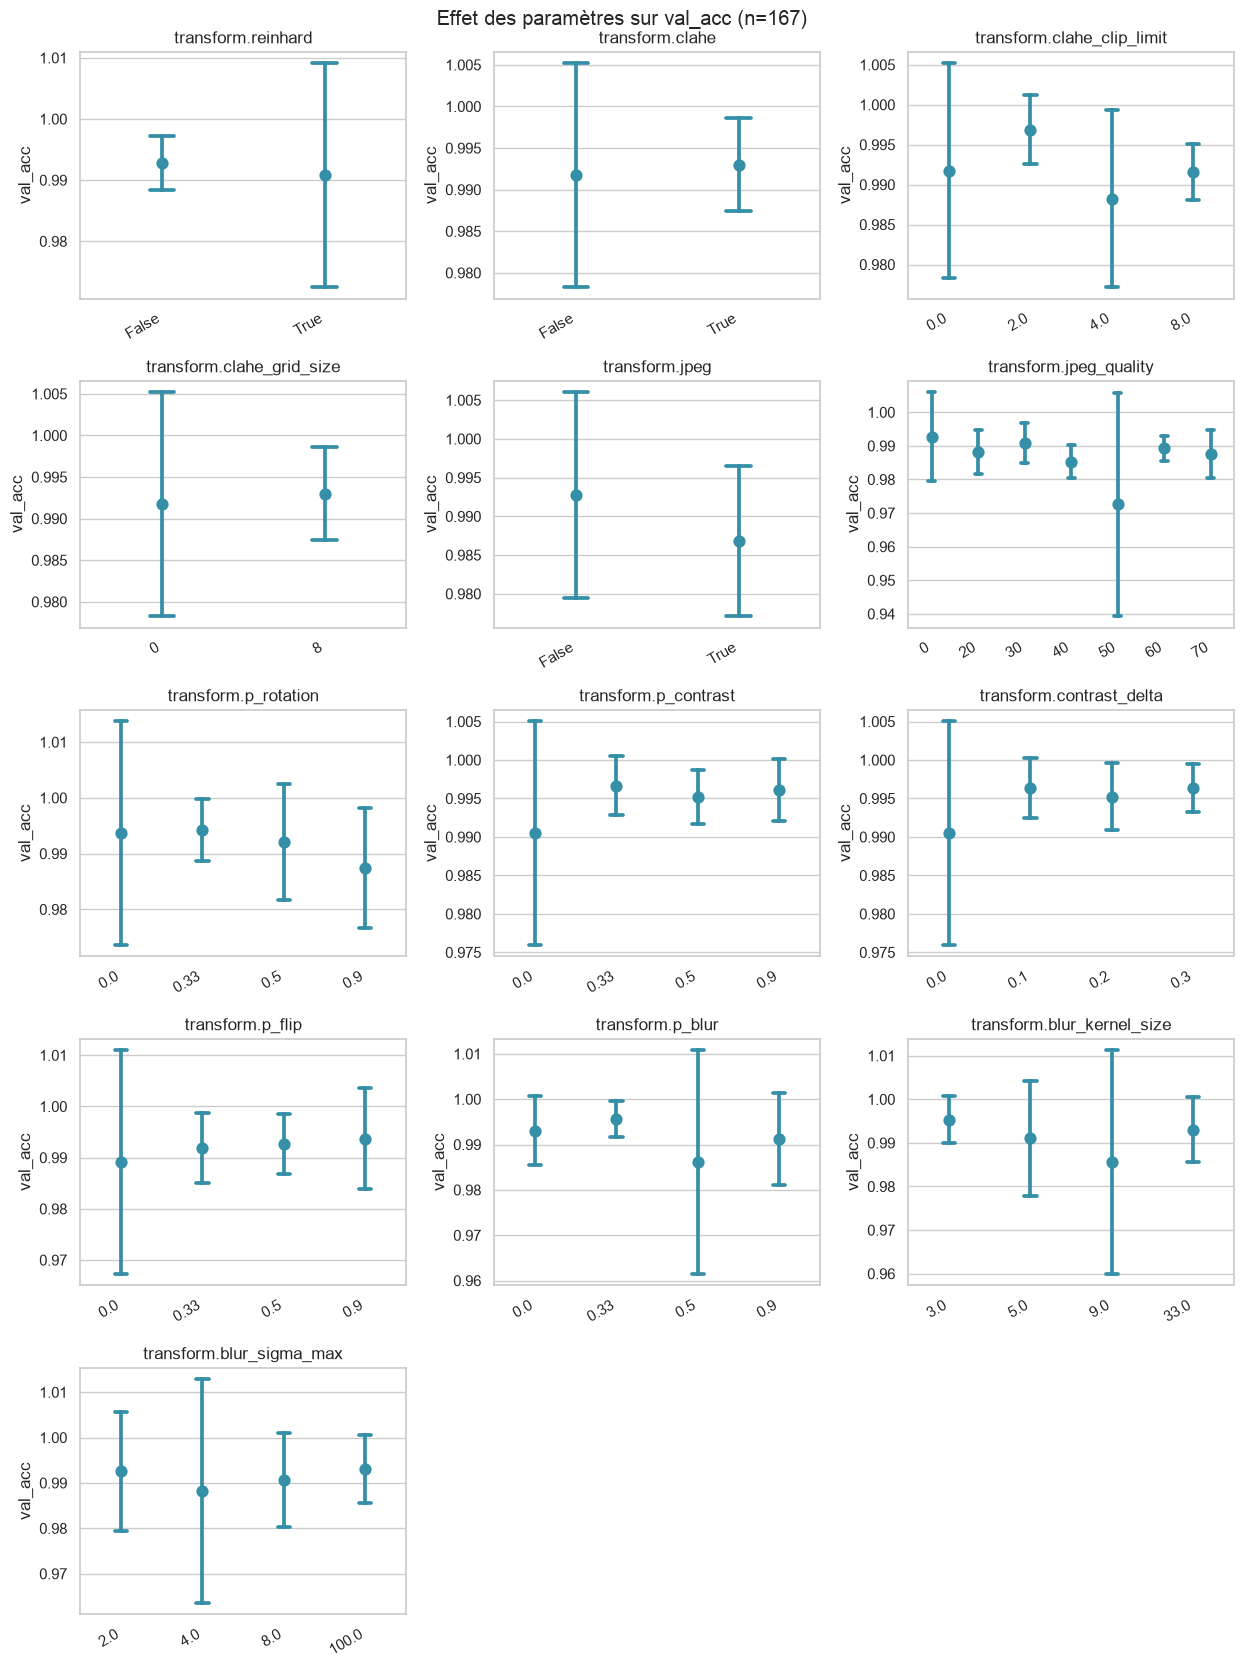

In [ ]:
transform_cols = [
    c for c in df_grid.columns if c.startswith("transform") and df_grid[c].nunique(False) > 1
]
metric = "val_acc"

sns.set_theme(style="whitegrid")
grid_accent = sns.color_palette("mako", 6)[3]


def _sort_key(v):
    if v == "NA":
        return (2, 0.0, "")
    if isinstance(v, bool | int | float):
        return (0, float(v), "")
    return (1, 0.0, str(v))


ncols = min(3, len(transform_cols))
nrows = -(-len(transform_cols) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.4 * nrows), squeeze=False)
for ax, col in zip(axes.flat, transform_cols, strict=False):
    plot_data = df_grid[[col, metric]].copy()
    plot_data[col] = plot_data[col].apply(lambda v: "NA" if pd.isna(v) else v)
    order = sorted(plot_data[col].unique(), key=_sort_key)
    sns.pointplot(
        data=plot_data,
        x=col,
        y=metric,
        order=order,
        color=grid_accent,
        errorbar="sd",
        capsize=0.15,
        linestyle="none",
        ax=ax,
    )
    ax.set_title(col)
    ax.set_xlabel(None)
    ax.tick_params(axis="x", rotation=30)
    for label in ax.get_xticklabels():
        label.set_ha("right")

for ax in axes.flat[len(transform_cols) :]:
    ax.set_visible(False)

fig.suptitle(f"Effet des paramètres sur {metric} (n={len(df_grid)})")
fig.tight_layout()
